In [21]:
import sys
from pathlib import Path
sys.path.append(str(Path("data_analysis/src/data_analysis").resolve()))


In [ ]:
from utils import load_db_engine, load_langsmith_client
db_engine = load_db_engine()
client = load_langsmith_client()


## Query to get users from database

In [61]:
from sqlalchemy import text
import pandas as pd
EMAIL_PATTERN = r"me\_%"
THREADS_QUERY = text(r"""
SELECT
    t.id AS thread_id,
    u.email,
    t.user_id
FROM thread AS t
JOIN "user" AS u ON u.id = t.user_id
WHERE u.email LIKE :email_pattern ESCAPE '\'
ORDER BY u.email, t.created_at;
""")

def get_target_users_threads(engine)->pd.DataFrame:
    params =  {"email_pattern": EMAIL_PATTERN}
    with engine.connect() as connection:
        threads = pd.read_sql(THREADS_QUERY, connection, params=params)
    return threads


## Prepare data

In [62]:
from thread_stats import ThreadStats
import asyncio


df = get_target_users_threads(db_engine)
stats = ThreadStats()
semaphore = asyncio.Semaphore(10)

async def get_thread_usage(thread_id):
    async with semaphore:
        thread = await client.get_thread(str(thread_id))
        return stats.summarize_thread_usage(thread)


results = await asyncio.gather(
    *(get_thread_usage(thread_id) for thread_id in df["thread_id"])
)

usage_df = pd.DataFrame(results)

df = pd.concat([df.reset_index(drop=True), usage_df.reset_index(drop=True)], axis=1)

## Gemini $0.25 (Text/image/video) per 1million tokens in USD
cost_factor = 0.25/(10**6)
df["estimated_cost"] = df["total_tokens"]*cost_factor


$18.93


## Analysis

In [81]:
df.head()
df.to_csv("thread_user_data.csv")

## Cost

In [71]:
total_cost = df["estimated_cost"].sum()
print(f"${total_cost:,.2f}")

$18.93


In [73]:
import pandas as pd

# Ensure datetime columns are parsed correctly
df["created_at"] = pd.to_datetime(df["created_at"], utc=True)
df["updated_at"] = pd.to_datetime(df["updated_at"], utc=True)

# Thread-level metric
df["thread_duration"] = df["updated_at"] - df["created_at"]

# Optional: duration in hours, easier for analysis/charting
df["thread_duration_hours"] = df["thread_duration"].dt.total_seconds() / 3600

# Create date column for active-day calculations
df["created_date"] = df["created_at"].dt.date

# User-level metrics
user_usage = (
    df.groupby(["user_id", "email"], as_index=False)
    .agg(
        threads_per_user=("thread_id", "nunique"),
        messages_per_user=("total_messages", "sum"),
        active_days_per_user=("created_date", "nunique"),
    )
)
user_usage.head()

,user_id,email,threads_per_user,messages_per_user,active_days_per_user
0,0209f8d8-af45-4676-b29c-296fd64aca59,me_999763@ucr.edu,1,26,1
1,0acbc4ce-8ae7-478f-830a-3444cbb31fd5,me_592452@ucr.edu,1,112,1
2,12f8066c-ae18-47e0-ab26-976c9824622d,me_982348@ucr.edu,1,212,1
3,1317a364-672e-48ca-9278-9225ab10c321,me_866476@ucr.edu,2,50,2
4,21e34cff-4c6e-4f52-a129-4f6941e5747b,me_324256@ucr.edu,3,42,2


In [77]:
user_usage.describe()

,threads_per_user,messages_per_user,active_days_per_user
count,39.000000,39.000000,39.000000
mean,2.512821,76.692308,1.564103
std,1.847784,73.936372,0.882427
min,1.000000,4.000000,1.000000
25%,1.000000,23.000000,1.000000
50%,2.000000,50.000000,1.000000
75%,3.000000,111.000000,2.000000
max,8.000000,302.000000,4.000000


In [76]:
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8-whitegrid")




# Distribution Of Threads Per User

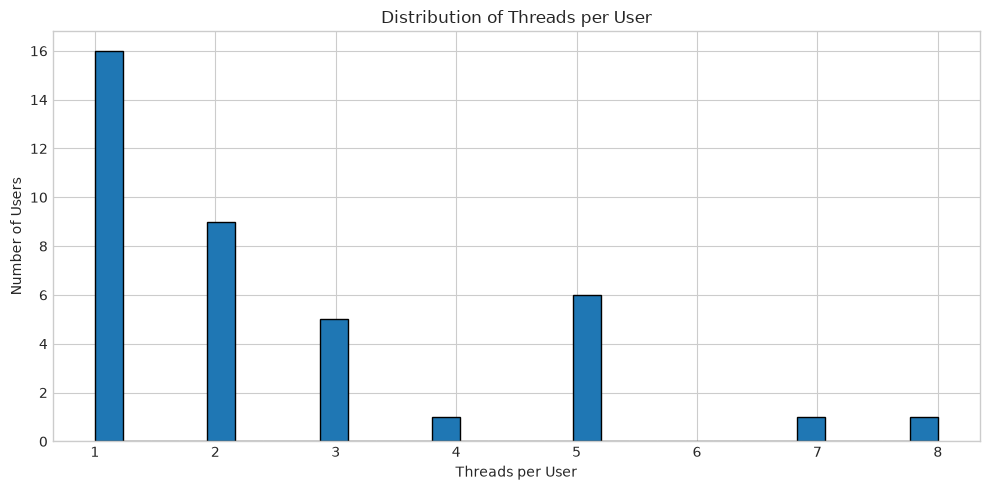

In [48]:
plt.figure(figsize=(10, 5))

plt.hist(user_usage["threads_per_user"], bins=30, edgecolor="black")

plt.title("Distribution of Threads per User")
plt.xlabel("Threads per User")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

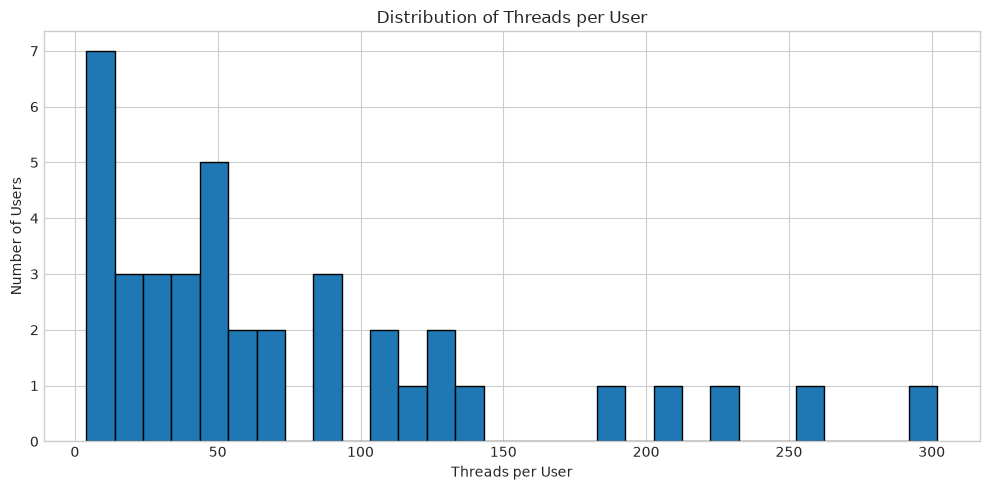

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(user_usage["messages_per_user"], bins=30, edgecolor="black")

plt.title("Distribution of Messages per User")
plt.xlabel("Threads per User")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

Top Users By Threads Created

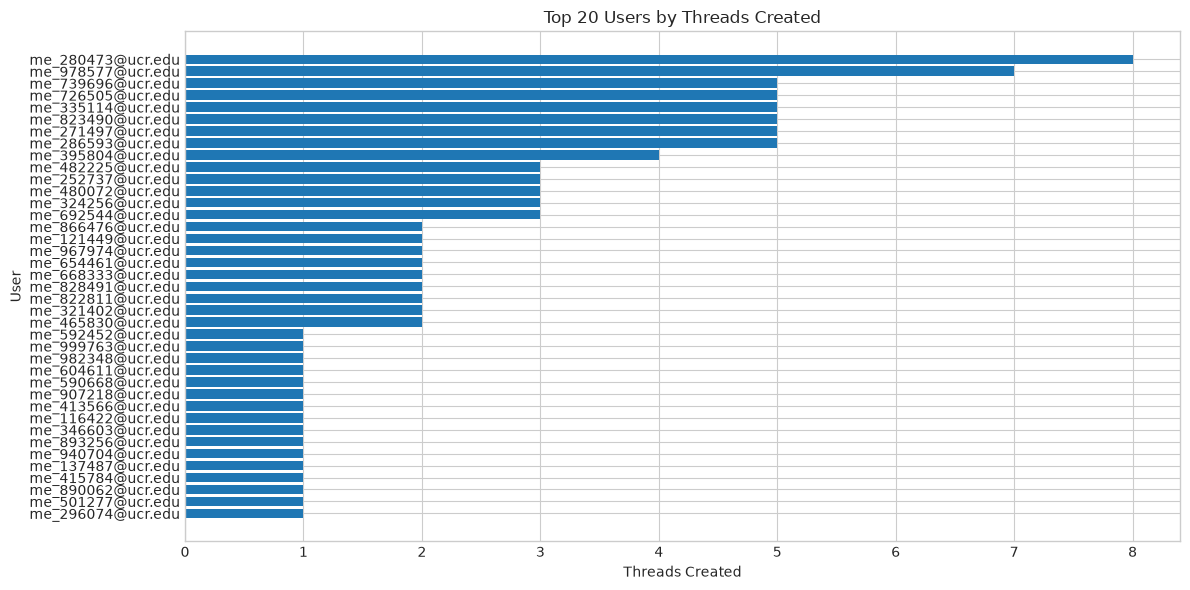

In [75]:
top_threads = user_usage.sort_values("threads_per_user", ascending=False)

plt.figure(figsize=(12, 6))

plt.barh(top_threads["email"], top_threads["threads_per_user"])
plt.gca().invert_yaxis()

plt.title("Top 20 Users by Threads Created")
plt.xlabel("Threads Created")
plt.ylabel("User")

plt.tight_layout()
plt.show()

Top Users By Total Messages

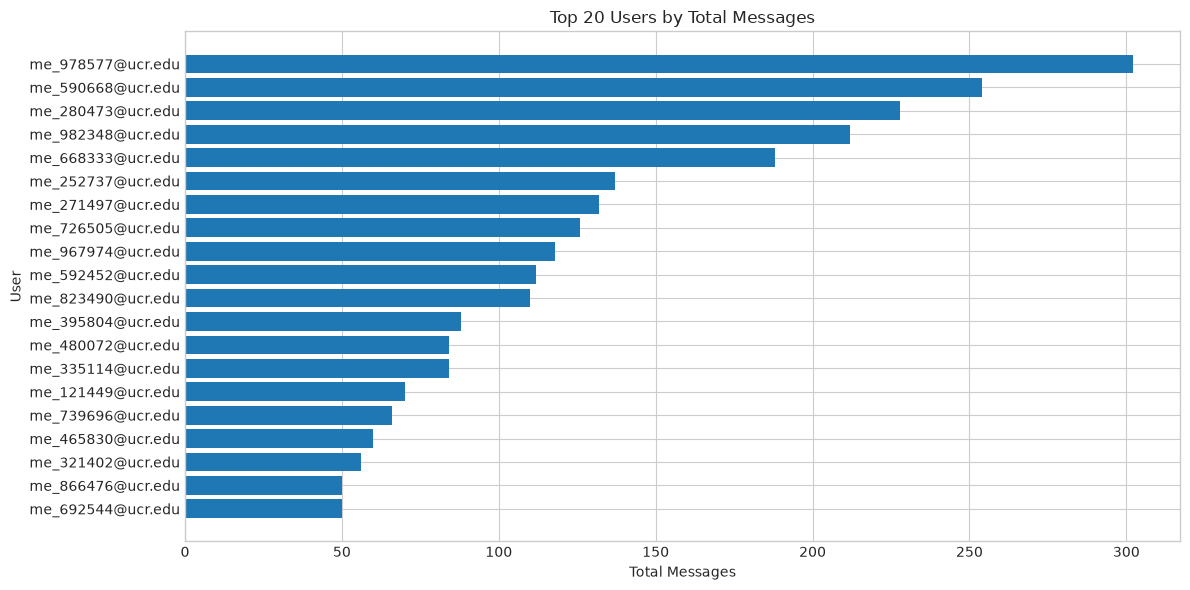

In [50]:
top_messages = user_usage.sort_values("messages_per_user", ascending=False).head(20)

plt.figure(figsize=(12, 6))

plt.barh(top_messages["email"], top_messages["messages_per_user"])
plt.gca().invert_yaxis()

plt.title("Top 20 Users by Total Messages")
plt.xlabel("Total Messages")
plt.ylabel("User")

plt.tight_layout()
plt.show()

Active Days Per User Distribution

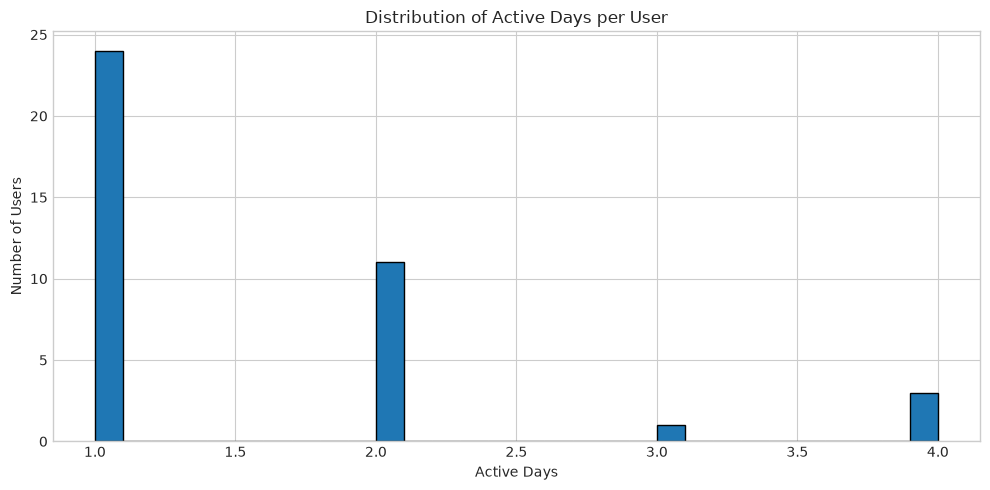

In [51]:
plt.figure(figsize=(10, 5))

plt.hist(user_usage["active_days_per_user"], bins=30, edgecolor="black")

plt.title("Distribution of Active Days per User")
plt.xlabel("Active Days")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

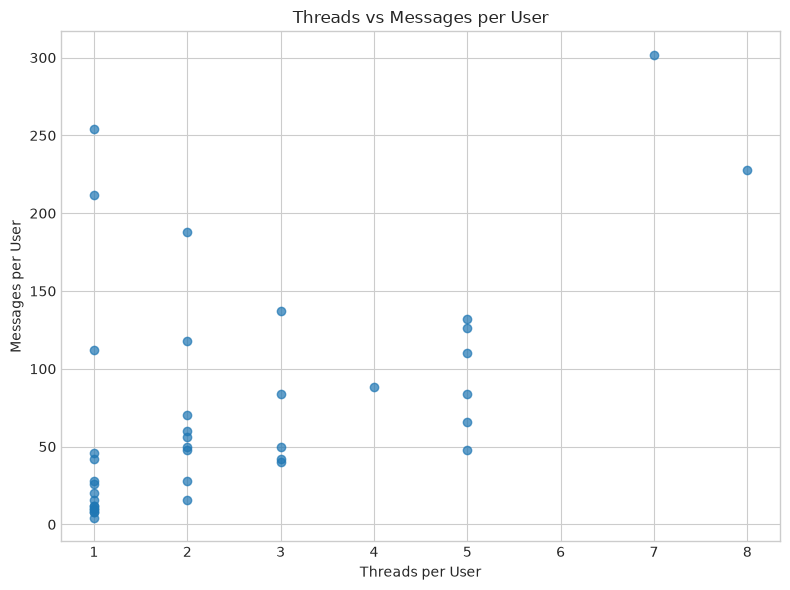

In [52]:
plt.figure(figsize=(8, 6))

plt.scatter(
    user_usage["threads_per_user"],
    user_usage["messages_per_user"],
    alpha=0.7
)

plt.title("Threads vs Messages per User")
plt.xlabel("Threads per User")
plt.ylabel("Messages per User")

plt.tight_layout()
plt.show()

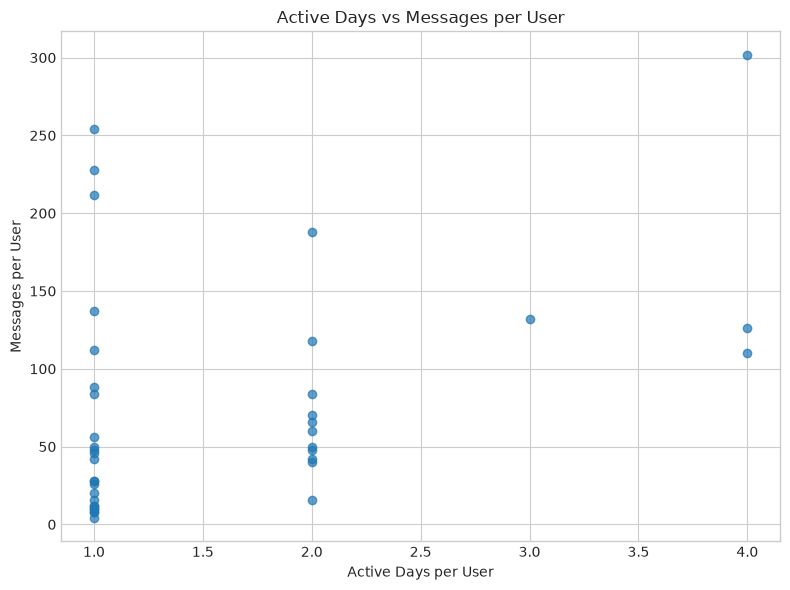

In [53]:
plt.figure(figsize=(8, 6))

plt.scatter(
    user_usage["active_days_per_user"],
    user_usage["messages_per_user"],
    alpha=0.7
)

plt.title("Active Days vs Messages per User")
plt.xlabel("Active Days per User")
plt.ylabel("Messages per User")

plt.tight_layout()
plt.show()

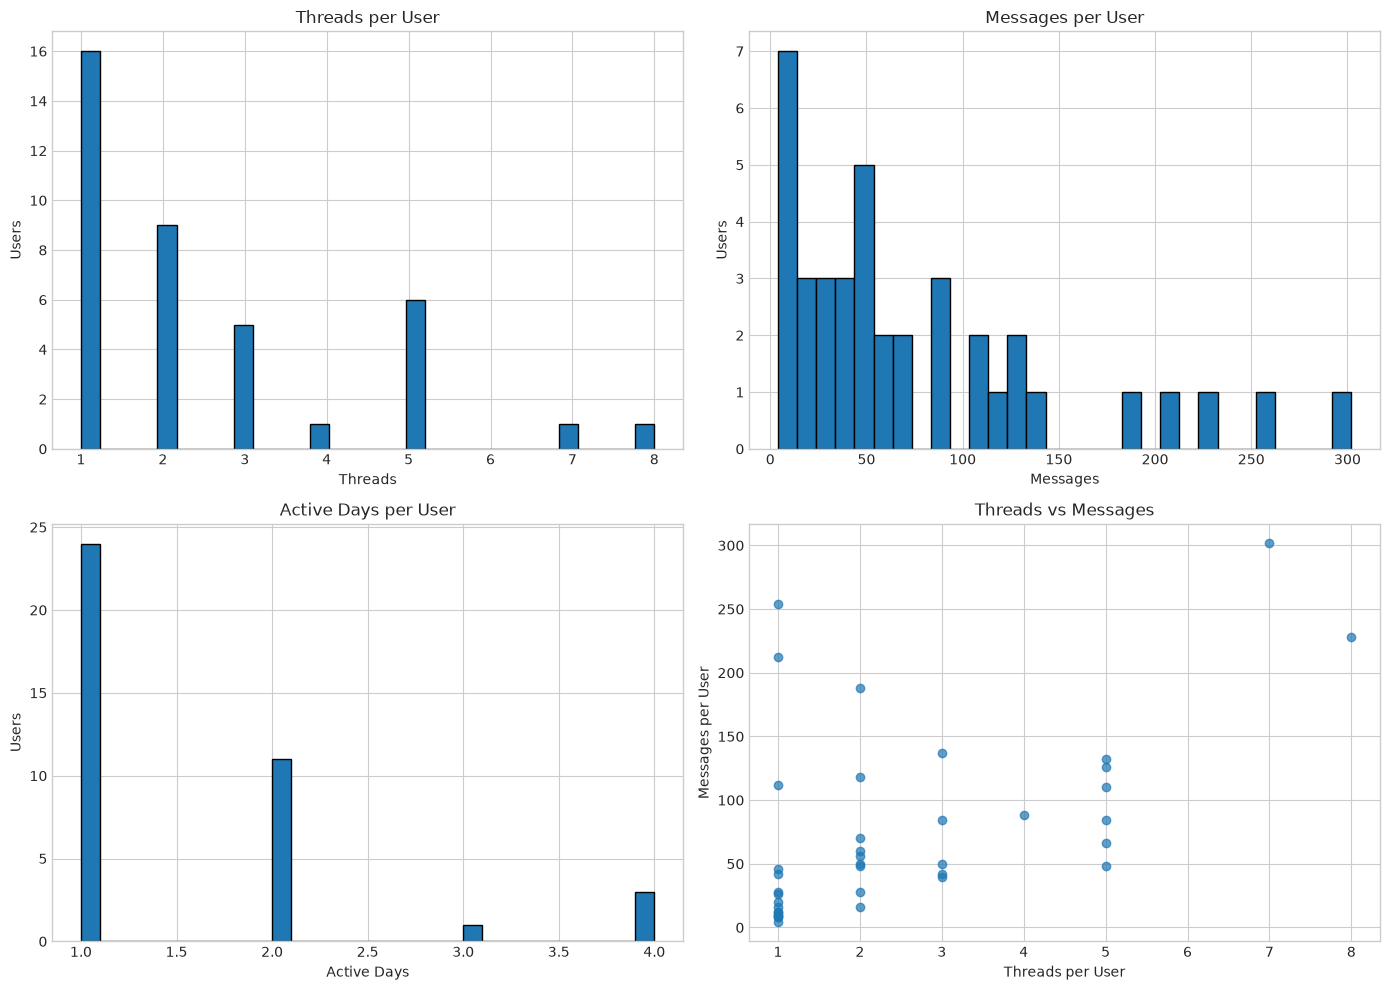

In [54]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(user_usage["threads_per_user"], bins=30, edgecolor="black")
axes[0, 0].set_title("Threads per User")
axes[0, 0].set_xlabel("Threads")
axes[0, 0].set_ylabel("Users")

axes[0, 1].hist(user_usage["messages_per_user"], bins=30, edgecolor="black")
axes[0, 1].set_title("Messages per User")
axes[0, 1].set_xlabel("Messages")
axes[0, 1].set_ylabel("Users")

axes[1, 0].hist(user_usage["active_days_per_user"], bins=30, edgecolor="black")
axes[1, 0].set_title("Active Days per User")
axes[1, 0].set_xlabel("Active Days")
axes[1, 0].set_ylabel("Users")

axes[1, 1].scatter(
    user_usage["threads_per_user"],
    user_usage["messages_per_user"],
    alpha=0.7
)
axes[1, 1].set_title("Threads vs Messages")
axes[1, 1].set_xlabel("Threads per User")
axes[1, 1].set_ylabel("Messages per User")

plt.tight_layout()
plt.show()

In [84]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

# Make sure numeric columns are actually numeric
numeric_cols = [
    "input_tokens",
    "output_tokens",
    "total_tokens",
    "estimated_cost",
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# User-level token + cost dataframe
token_cost_usage = (
    df.groupby(["user_id", "email"], as_index=False)
    .agg(
        total_input_tokens=("input_tokens", "sum"),
        total_output_tokens=("output_tokens", "sum"),
        total_tokens=("total_tokens", "sum"),
        total_estimated_cost=("estimated_cost", "sum"),
        avg_tokens_per_thread=("total_tokens", "mean"),
        avg_cost_per_thread=("estimated_cost", "mean"),
        threads=("thread_id", "nunique"),
    )
)

token_cost_usage["input_token_share"] = (
    token_cost_usage["total_input_tokens"] / token_cost_usage["total_tokens"]
)

token_cost_usage["output_token_share"] = (
    token_cost_usage["total_output_tokens"] / token_cost_usage["total_tokens"]
)

token_cost_usage["cost_per_thread"] = (
    token_cost_usage["total_estimated_cost"] / token_cost_usage["threads"]
)

token_cost_usage
token_cost_usage.to_csv("token_cost_usage.csv")

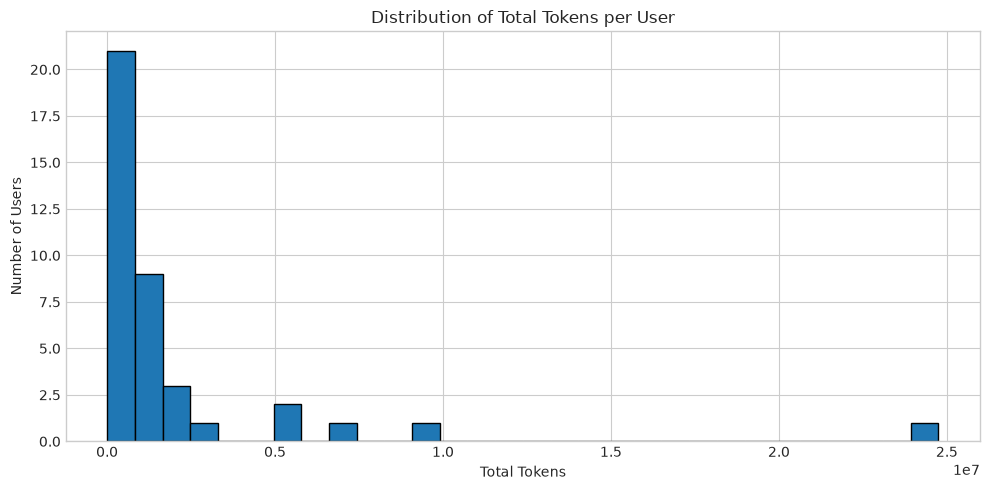

In [58]:
# 1. Distribution of total tokens per user
plt.figure(figsize=(10, 5))

plt.hist(token_cost_usage["total_tokens"], bins=30, edgecolor="black")

plt.title("Distribution of Total Tokens per User")
plt.xlabel("Total Tokens")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

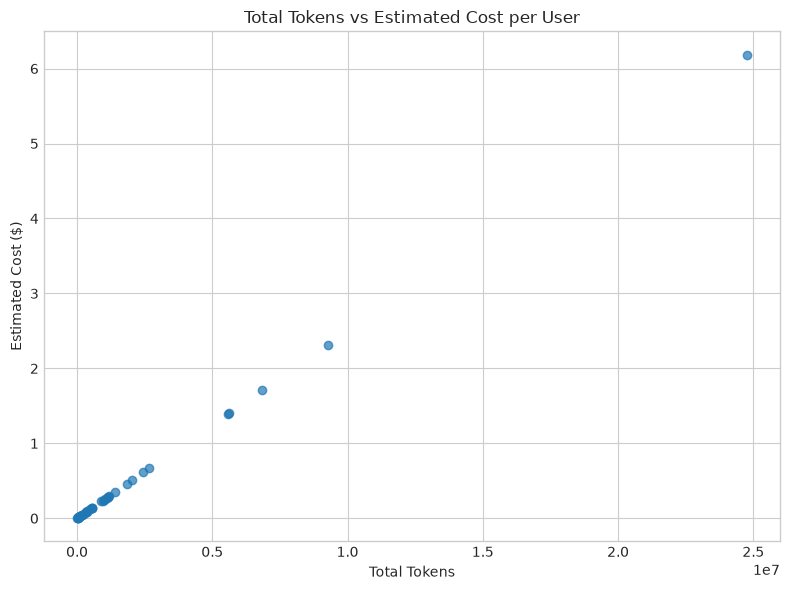

In [59]:
# 5. Total tokens vs estimated cost
plt.figure(figsize=(8, 6))

plt.scatter(
    token_cost_usage["total_tokens"],
    token_cost_usage["total_estimated_cost"],
    alpha=0.7
)

plt.title("Total Tokens vs Estimated Cost per User")
plt.xlabel("Total Tokens")
plt.ylabel("Estimated Cost ($)")

plt.tight_layout()
plt.show()

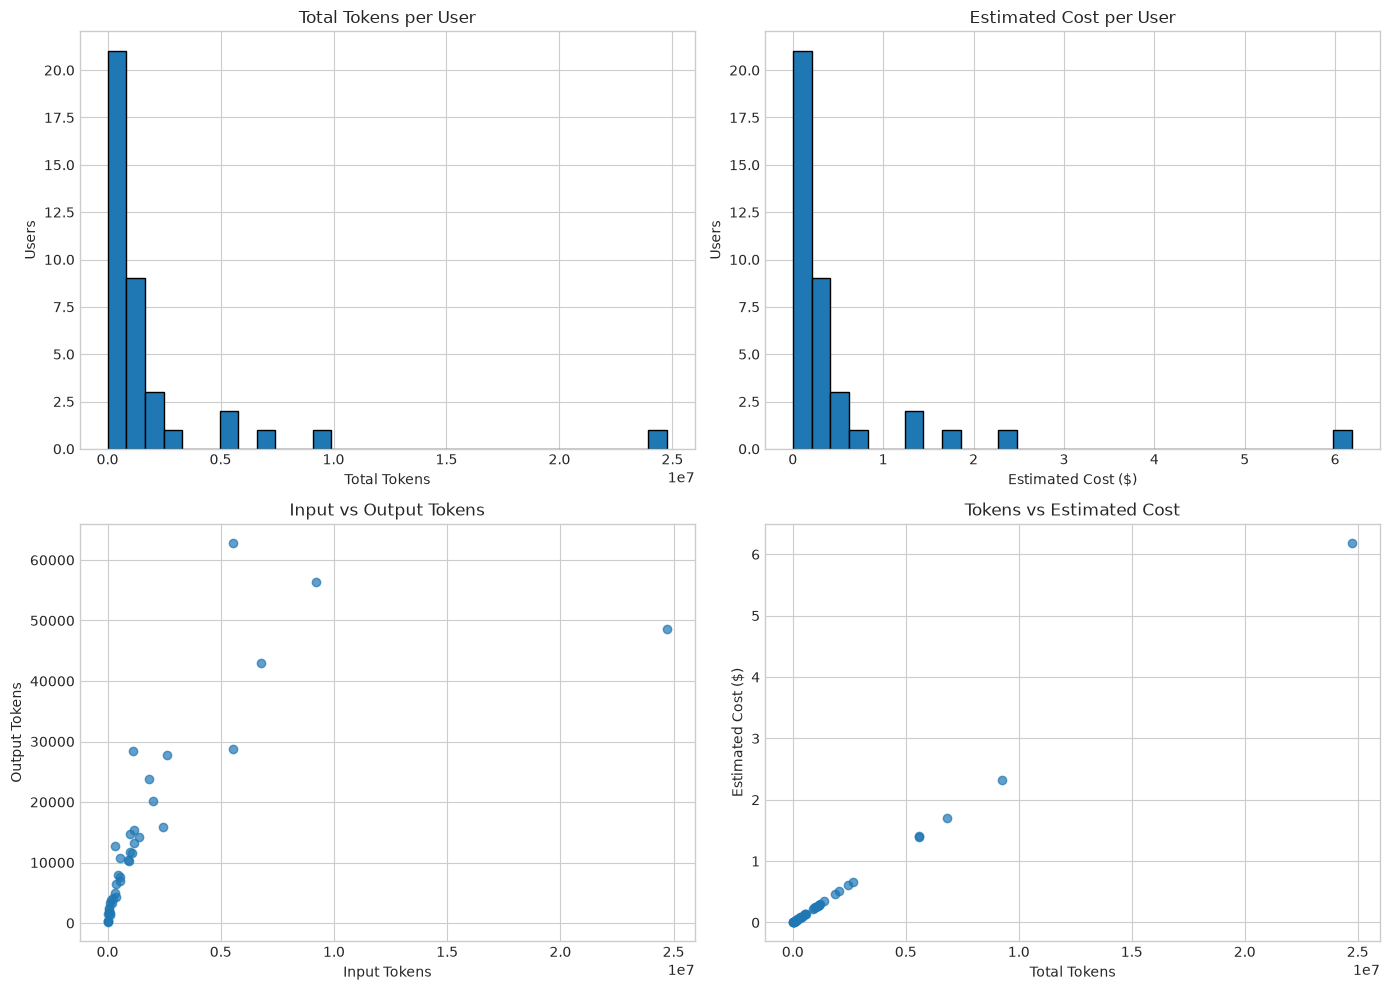

In [60]:
# 7. Dashboard view
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(token_cost_usage["total_tokens"], bins=30, edgecolor="black")
axes[0, 0].set_title("Total Tokens per User")
axes[0, 0].set_xlabel("Total Tokens")
axes[0, 0].set_ylabel("Users")

axes[0, 1].hist(token_cost_usage["total_estimated_cost"], bins=30, edgecolor="black")
axes[0, 1].set_title("Estimated Cost per User")
axes[0, 1].set_xlabel("Estimated Cost ($)")
axes[0, 1].set_ylabel("Users")

axes[1, 0].scatter(
    token_cost_usage["total_input_tokens"],
    token_cost_usage["total_output_tokens"],
    alpha=0.7
)
axes[1, 0].set_title("Input vs Output Tokens")
axes[1, 0].set_xlabel("Input Tokens")
axes[1, 0].set_ylabel("Output Tokens")

axes[1, 1].scatter(
    token_cost_usage["total_tokens"],
    token_cost_usage["total_estimated_cost"],
    alpha=0.7
)
axes[1, 1].set_title("Tokens vs Estimated Cost")
axes[1, 1].set_xlabel("Total Tokens")
axes[1, 1].set_ylabel("Estimated Cost ($)")

plt.tight_layout()
plt.show()